
# Lab 5 — Bonus: three test signals

**CSC 413 Robotics · Week 5 Assignment 1 · Student ID: 70**

Bonus task: three types of complex signal with the identified model checked on each. This notebook repeats section 4.4 of the assignment for the **square wave, chirp and triangle** on both motors:

1. the parameters $T_m$, $k_e$ and the dead zone are identified from the step series;
2. the motor is simulated with the recorded PWM of each signal, with and without the dead zone;
3. measured and simulated angle and speed are compared, with RMSE and fit %;
4. for the chirp, the amplitude ratio is compared with $1/(k_e\sqrt{1+(2\pi f T_m)^2})$.

Battery voltage: 11.2 V during all six runs. Cells marked ✍️ need text in your own words.


In [1]:
# In Colab: run this cell, click "Choose Files", and select ALL the .txt files at once (Ctrl+A / Cmd+A in the file window).
# The cell puts them into a motor_data folder. Outside Colab it does nothing.
import os
try:
    from google.colab import files
    os.makedirs('motor_data', exist_ok=True)
    for name in files.upload():
        os.replace(name, os.path.join('motor_data', name))
    print('Uploaded:', sorted(os.listdir('motor_data')))
except ImportError:
    print('Not running in Colab: using the motor_data folder next to this notebook.')

Saving battery.txt to battery.txt
Saving ch_signal_chirp_M3.txt to ch_signal_chirp_M3.txt
Saving ch_signal_chirp_M4.txt to ch_signal_chirp_M4.txt
Saving ch_signal_square_M3.txt to ch_signal_square_M3.txt
Saving ch_signal_square_M4.txt to ch_signal_square_M4.txt
Saving ch_signal_triangle_M3.txt to ch_signal_triangle_M3.txt
Saving ch_signal_triangle_M4.txt to ch_signal_triangle_M4.txt
Saving charos_1at_b_M3_real(3).txt to charos_1at_b_M3_real(3).txt
Saving charos_1at_b_M4_real(3).txt to charos_1at_b_M4_real(3).txt
Saving charos_1at_M3_real(4).txt to charos_1at_M3_real(4).txt
Saving charos_1at_M3_sim(4).txt to charos_1at_M3_sim(4).txt
Saving charos_1at_M4_real(3).txt to charos_1at_M4_real(3).txt
Saving charos_1at_M4_sim(3).txt to charos_1at_M4_sim(3).txt
Saving repeat_M4(3).txt to repeat_M4(3).txt
Uploaded: ['battery.txt', 'ch_signal_chirp_M3.txt', 'ch_signal_chirp_M4.txt', 'ch_signal_square_M3.txt', 'ch_signal_square_M4.txt', 'ch_signal_triangle_M3.txt', 'ch_signal_triangle_M4.txt', 'cha

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# --- Where the raw files are ---------------------------------------------------
# In Colab, either upload the motor_data folder next to this notebook, or clone the repo:
#   !git clone https://github.com/charosmuxammadiyeva/Robotics_fall.git
#   DATA_DIR = 'Robotics_fall/Assignment_1/motor_data'
DATA_DIR = 'motor_data'

MOTORS = ['M3', 'M4']
STEP_FILES     = {'M3': 'charos_1at_M3_real(4).txt', 'M4': 'charos_1at_M4_real(3).txt'}
REPEAT_FILES   = {'M4': 'repeat_M4(3).txt'}
PM60_FILES     = {'M3': 'charos_1at_b_M3_real(3).txt', 'M4': 'charos_1at_b_M4_real(3).txt'}
SIM_STEP_FILES = {'M3': 'charos_1at_M3_sim(4).txt', 'M4': 'charos_1at_M4_sim(3).txt'}

# Complex signals recorded with Program B. Keep these numbers identical to the TRIK program.
SIGNALS = {
    'square':   dict(A=60, P=1.0),                      # amplitude %, period s
    'chirp':    dict(A=60, f0=0.2, f1=5.0, T=10.0),     # amplitude %, start/end frequency Hz, duration s
    'triangle': dict(A=60, P=2.0),
}
SIGNAL_FILE = 'ch_signal_{sig}_{motor}.txt'

SMOOTH_WINDOW = 5         # moving-average window for the measured speed, samples (about 100 ms at 20 ms sampling)
LINEAR_RANGE  = (20, 90)  # |PWM| range treated as the linear part of speed vs PWM
MOVING_THRESHOLD = 0.2    # rad/s; below this a level counts as "did not move"

def _norm(s):
    s = os.path.splitext(s)[0].lower()
    return ''.join(ch for ch in s if ch.isalnum())

def path(name):
    # Exact name first; otherwise accept the same file renamed by the browser or Colab,
    # e.g. 'repeat_M4(3) (1).txt' or 'repeat_M4_3_.txt' for 'repeat_M4(3).txt'.
    p = os.path.join(DATA_DIR, name)
    if os.path.isfile(p) or not os.path.isdir(DATA_DIR):
        return p
    want = _norm(name)
    hits = sorted(f for f in os.listdir(DATA_DIR) if _norm(f).startswith(want))
    return os.path.join(DATA_DIR, hits[0]) if hits else p

def exists(name): return os.path.isfile(path(name))

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"No '{DATA_DIR}' folder: run the upload cell above first.")
print('Files in', DATA_DIR)
for f in sorted(os.listdir(DATA_DIR)):
    print('  ', f)
needed = list(STEP_FILES.values()) + ['battery.txt']
missing = [f for f in needed if not exists(f)]
if missing:
    print('\nMISSING (upload these):', missing)

Files in motor_data
   battery.txt
   ch_signal_chirp_M3.txt
   ch_signal_chirp_M4.txt
   ch_signal_square_M3.txt
   ch_signal_square_M4.txt
   ch_signal_triangle_M3.txt
   ch_signal_triangle_M4.txt
   charos_1at_M3_real(4).txt
   charos_1at_M3_sim(4).txt
   charos_1at_M4_real(3).txt
   charos_1at_M4_sim(3).txt
   charos_1at_b_M3_real(3).txt
   charos_1at_b_M4_real(3).txt
   repeat_M4(3).txt


## 1. Identified parameters (from the step series)

In [3]:
def load(name):
    # Raw columns: encoder angle [deg], time() [ms], PWM [%]
    a = np.loadtxt(path(name), delimiter=',', ndmin=2)
    return {'theta': np.deg2rad(a[:, 0]), 't': a[:, 1] / 1000.0, 'pwm': a[:, 2], 'raw': a}

def segments(d):
    # Split a record wherever the commanded PWM changes
    pwm = d['pwm']
    cuts = np.r_[0, np.flatnonzero(np.diff(pwm) != 0) + 1, len(pwm)]
    segs = []
    for lo, hi in zip(cuts[:-1], cuts[1:]):
        segs.append(dict(pwm=float(pwm[lo]), lo=lo, hi=hi,
                         t=d['t'][lo:hi] - d['t'][lo],
                         theta=d['theta'][lo:hi] - d['theta'][lo]))
    return segs

steps     = {m: load(STEP_FILES[m]) for m in MOTORS}

for m, d in steps.items():
    dt = np.diff(d['t']) * 1000
    print(f"{m}: {len(d['t'])} samples over {d['t'][-1] - d['t'][0]:.1f} s; "
          f"sampling interval mean {dt.mean():.1f} ms (min {dt.min():.0f}, max {dt.max():.0f})")

M3: 3232 samples over 63.2 s; sampling interval mean 19.5 ms (min 12, max 47)
M4: 3235 samples over 63.1 s; sampling interval mean 19.5 ms (min 13, max 46)


In [4]:
def read_battery():
    if not exists('battery.txt'):
        return pd.DataFrame(columns=['run', 'before_V', 'after_V'])
    return pd.read_csv(path('battery.txt'), comment='#', skipinitialspace=True)

battery = read_battery()

def battery_voltage(run):
    r = battery[battery.run == run]
    if r.empty:
        return np.nan
    v = r[['before_V', 'after_V']].to_numpy(dtype=float).ravel()
    return float(np.nanmean(v)) if np.any(~np.isnan(v)) else np.nan

U_batt, U_note = {}, {}
for m in MOTORS:
    v = battery_voltage(f'steps_{m}')
    if np.isnan(v):
        # step series not measured: fall back to the voltage logged during this motor's complex-signal runs
        sig_v = [battery_voltage(f'signal_{s}_{m}') for s in SIGNALS]
        sig_v = [x for x in sig_v if not np.isnan(x)]
        v = float(np.mean(sig_v)) if sig_v else np.nan
        U_note[m] = 'assumed from complex-signal runs (step series not measured)' if sig_v else 'not available'
    else:
        U_note[m] = 'measured during the step series'
    U_batt[m] = v
print(battery.to_string(index=False))
for m in MOTORS:
    print(f'U_battery for k_e, {m}: {U_batt[m]:.2f} V  ({U_note[m]})')

               run  before_V  after_V
          steps_M3       NaN      NaN
          steps_M4       NaN      NaN
         repeat_M4       NaN      NaN
           pm60_M3       NaN      NaN
           pm60_M4       NaN      NaN
  signal_square_M3      11.2     11.2
   signal_chirp_M3      11.2     11.2
signal_triangle_M3      11.2     11.2
  signal_square_M4      11.2     11.2
   signal_chirp_M4      11.2     11.2
signal_triangle_M4      11.2     11.2
U_battery for k_e, M3: 11.20 V  (assumed from complex-signal runs (step series not measured))
U_battery for k_e, M4: 11.20 V  (assumed from complex-signal runs (step series not measured))


In [5]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def coast_model(t, w0, T_c):
    return w0 * T_c * (1 - np.exp(-t / T_c))

def fit_steps(d):
    rows, coast = [], []
    segs = segments(d)
    for i, s in enumerate(segs):
        if len(s['t']) < 5:
            continue
        if s['pwm'] != 0:
            p0 = [s['theta'][-1] / s['t'][-1], 0.1]
            popt, pcov = optimize.curve_fit(model, s['t'], s['theta'], p0=p0,
                                            bounds=([-np.inf, 1e-3], [np.inf, 2]), maxfev=20000)
            err = np.sqrt(np.diag(pcov))
            rows.append(dict(pwm=s['pwm'], speed=popt[0], speed_err=err[0],
                             T_m=popt[1], T_m_err=err[1], seg=s))
        elif i > 0 and segs[i - 1]['pwm'] != 0 and rows and rows[-1]['pwm'] == segs[i - 1]['pwm']:
            prev = rows[-1]
            try:
                popt, _ = optimize.curve_fit(coast_model, s['t'], s['theta'], p0=[prev['speed'], 0.1],
                                             bounds=([-np.inf, 1e-3], [np.inf, 2]), maxfev=20000)
                coast.append(dict(pwm_before=prev['pwm'], speed_before=prev['speed'],
                                  T_m_before=prev['T_m'], w0=popt[0], T_coast=popt[1],
                                  coast_angle=s['theta'][-1], seg=s))
            except RuntimeError:
                pass
    f = pd.DataFrame(rows)
    f['reliable'] = (f.T_m_err < 0.5 * f.T_m) & (f.T_m > 0.005)
    return f, pd.DataFrame(coast)

fits, coasts = {}, {}
for m in MOTORS:
    fits[m], coasts[m] = fit_steps(steps[m])



In [6]:
def direction_params(f, Ub):
    out = {}
    for name, sgn in [('Forward', 1), ('Backward', -1)]:
        d = f[np.sign(f.pwm) == sgn]
        lin = d[(d.pwm.abs() >= LINEAR_RANGE[0]) & (d.pwm.abs() <= LINEAR_RANGE[1])]
        slope, icpt = np.polyfit(lin.pwm, lin.speed, 1)
        moved = d[d.speed.abs() > MOVING_THRESHOLD].pwm.abs()
        stopped = d[d.speed.abs() <= MOVING_THRESHOLD].pwm.abs()
        dz_low = float(stopped.max()) if len(stopped) else 0.0      # largest level that did not move
        dz_high = float(moved.min())                                 # smallest level that moved
        rel = d[d.reliable]
        top = d.loc[d.pwm.abs().idxmax()]
        lin_pred = slope * top.pwm + icpt
        out[name] = dict(
            slope=abs(slope), slope_signed=slope, icpt=icpt,
            dz=dz_low, dz_high=dz_high,
            dz_text=(f'< {dz_high:g} (not resolved)' if dz_low == 0 else f'{dz_low:g}–{dz_high:g}'),
            k_e=Ub / (100 * abs(slope)) if np.isfinite(Ub) else np.nan,
            T_m=rel.T_m.mean(), T_m_std=rel.T_m.std(),
            U_batt=Ub,
            sat_dev=100 * (top.speed - lin_pred) / lin_pred,
            zero_cross=-icpt / slope)
    return out

P = {m: direction_params(fits[m], U_batt[m]) for m in MOTORS}

for m in MOTORS:
    tab = pd.DataFrame({
        'Direction': list(P[m]),
        'Dead zone, % PWM': [p['dz_text'] for p in P[m].values()],
        'Slope, rad/s per % PWM': [p['slope'] for p in P[m].values()],
        'k_e, V·s/rad': [p['k_e'] for p in P[m].values()],
        'Mean T_m, s': [p['T_m'] for p in P[m].values()],
        'U_battery, V': [p['U_batt'] for p in P[m].values()],
    })
    print(f'\n=== Motor {m} ===')
    print(tab.round(4).to_string(index=False))
    for k, p in P[m].items():
        print(f"  {k}: line intercept b = {p['icpt']:+.2f} rad/s (line reaches 0 at PWM {p['zero_cross']:+.1f} %), "
              f"deviation from line at full PWM {p['sat_dev']:+.1f} %, T_m spread (std) {p['T_m_std']:.3f} s")


=== Motor M3 ===
Direction    Dead zone, % PWM  Slope, rad/s per % PWM  k_e, V·s/rad  Mean T_m, s  U_battery, V
  Forward < 10 (not resolved)                  0.1021        1.0973       0.1778          11.2
 Backward < 10 (not resolved)                  0.0979        1.1444       0.2051          11.2
  Forward: line intercept b = +4.67 rad/s (line reaches 0 at PWM -45.8 %), deviation from line at full PWM -0.4 %, T_m spread (std) 0.110 s
  Backward: line intercept b = -4.83 rad/s (line reaches 0 at PWM +49.3 %), deviation from line at full PWM -0.6 %, T_m spread (std) 0.118 s

=== Motor M4 ===
Direction    Dead zone, % PWM  Slope, rad/s per % PWM  k_e, V·s/rad  Mean T_m, s  U_battery, V
  Forward < 10 (not resolved)                  0.1072        1.0445       0.1313          11.2
 Backward < 10 (not resolved)                  0.1012        1.1067       0.1644          11.2
  Forward: line intercept b = +3.43 rad/s (line reaches 0 at PWM -32.0 %), deviation from line at full PWM +3.1 %


## 2. Model versus real motor on each signal
The model is the first-order motor with the identified parameters of each direction:

$$\frac{d\omega}{dt} = \frac{\omega_{ss}(\text{PWM}) - \omega}{T_m}, \qquad \omega_{ss} = a\cdot\text{PWM} + b \;\;(\text{line fitted in section 1, } a = U_{battery}/(100\,k_e))$$

with the mean $T_m$ of each direction. **With dead zone**: $\omega_{ss}=0$ when |PWM| is inside the identified dead zone. The recorded PWM is held constant between samples. Measured speed: `np.gradient` of the angle, moving average of `SMOOTH_WINDOW` = 5 samples.


In [7]:
def zoh(t_log, x_log):
    # Zero-order hold: the value commanded at the last sample before t
    def f(t):
        i = np.searchsorted(t_log, t, side='right') - 1
        return x_log[min(max(i, 0), len(x_log) - 1)]
    return f

def simulate(t_log, pwm_log, wss_fn, tm_fn):
    u_of_t = zoh(t_log, pwm_log)
    def rhs(state, t):
        w, th = state
        u = u_of_t(t)
        return [(wss_fn(u) - w) / tm_fn(u), w]
    y = odeint(rhs, [0.0, 0.0], t_log, hmax=np.median(np.diff(t_log)) / 2)
    return y[:, 1], y[:, 0]          # angle, speed

def model_A_fns(Pm, offset=True, dead_zone=True):
    def wss(u):
        p = Pm['Forward'] if u > 0 else Pm['Backward']
        if u == 0 or (dead_zone and abs(u) <= p['dz']):
            return 0.0
        return p['slope_signed'] * u + (p['icpt'] if offset else 0.0)
    def tm(u):
        return (Pm['Forward'] if u >= 0 else Pm['Backward'])['T_m']
    return wss, tm

def model_B_fns(f, c):
    T_coast = float(np.median(c.T_coast)) if len(c) else float(f[f.reliable].T_m.median())
    w_tab = f.sort_values('pwm')
    w_x = np.r_[w_tab.pwm.to_numpy(), 0.0]; w_y = np.r_[w_tab.speed.to_numpy(), 0.0]
    o = np.argsort(w_x); w_x, w_y = w_x[o], w_y[o]
    g = f[f.reliable]
    t_x = np.r_[g.pwm.to_numpy(), 0.0]; t_y = np.r_[g.T_m.to_numpy(), T_coast]
    o = np.argsort(t_x); t_x, t_y = t_x[o], t_y[o]
    return (lambda u: float(np.interp(u, w_x, w_y))), (lambda u: float(np.interp(u, t_x, t_y)))

def measured_speed(t, th, window=SMOOTH_WINDOW):
    w = np.gradient(th, t)
    if window > 1:
        k = np.ones(window) / window
        return w, np.convolve(w, k, mode='same')
    return w, w

def fit_pct(y, yhat):
    return 100 * (1 - np.linalg.norm(y - yhat) / np.linalg.norm(y - np.mean(y)))

def rmse(y, yhat):
    return float(np.sqrt(np.mean((y - yhat) ** 2)))

MODELS = {
    'with dead zone':    lambda m: model_A_fns(P[m], offset=True, dead_zone=True),
    'without dead zone': lambda m: model_A_fns(P[m], offset=True, dead_zone=False),
}

available = [(sig, m) for sig in SIGNALS for m in MOTORS if exists(SIGNAL_FILE.format(sig=sig, motor=m))]
missing   = [SIGNAL_FILE.format(sig=sig, motor=m) for sig in SIGNALS for m in MOTORS
             if not exists(SIGNAL_FILE.format(sig=sig, motor=m))]
print('Complex-signal files found:', [SIGNAL_FILE.format(sig=s, motor=m) for s, m in available] or 'none')
if missing:
    print('Not recorded yet:', missing)

results, runs = [], {}
for sig, m in available:
    d = load(SIGNAL_FILE.format(sig=sig, motor=m))
    t = d['t'] - d['t'][0]; th = d['theta'] - d['theta'][0]; u = d['pwm']
    w_raw, w_meas = measured_speed(t, th)
    run = dict(t=t, theta=th, pwm=u, w_raw=w_raw, w=w_meas, sim={})
    for name, make in MODELS.items():
        wss, tm = make(m)
        th_hat, w_hat = simulate(t, u, wss, tm)
        run['sim'][name] = (th_hat, w_hat)
        results.append(dict(signal=sig, motor=m, model=name,
                            angle_RMSE_rad=rmse(th, th_hat), angle_fit_pct=fit_pct(th, th_hat),
                            speed_RMSE=rmse(w_meas, w_hat), speed_fit_pct=fit_pct(w_meas, w_hat)))
    runs[(sig, m)] = run

res = pd.DataFrame(results)
if len(res):
    print(res.round(2).to_string(index=False))

Complex-signal files found: ['ch_signal_square_M3.txt', 'ch_signal_square_M4.txt', 'ch_signal_chirp_M3.txt', 'ch_signal_chirp_M4.txt', 'ch_signal_triangle_M3.txt', 'ch_signal_triangle_M4.txt']
  signal motor             model  angle_RMSE_rad  angle_fit_pct  speed_RMSE  speed_fit_pct
  square    M3    with dead zone            3.64        -144.85        1.38          77.66
  square    M3 without dead zone            3.64        -144.85        1.38          77.66
  square    M4    with dead zone            4.75        -275.38        1.23          78.45
  square    M4 without dead zone            4.75        -275.38        1.23          78.45
   chirp    M3    with dead zone            3.78        -197.27        1.15          65.77
   chirp    M3 without dead zone            3.78        -197.27        1.15          65.77
   chirp    M4    with dead zone            5.16        -401.24        1.27          58.14
   chirp    M4 without dead zone            5.16        -401.24        1.27    

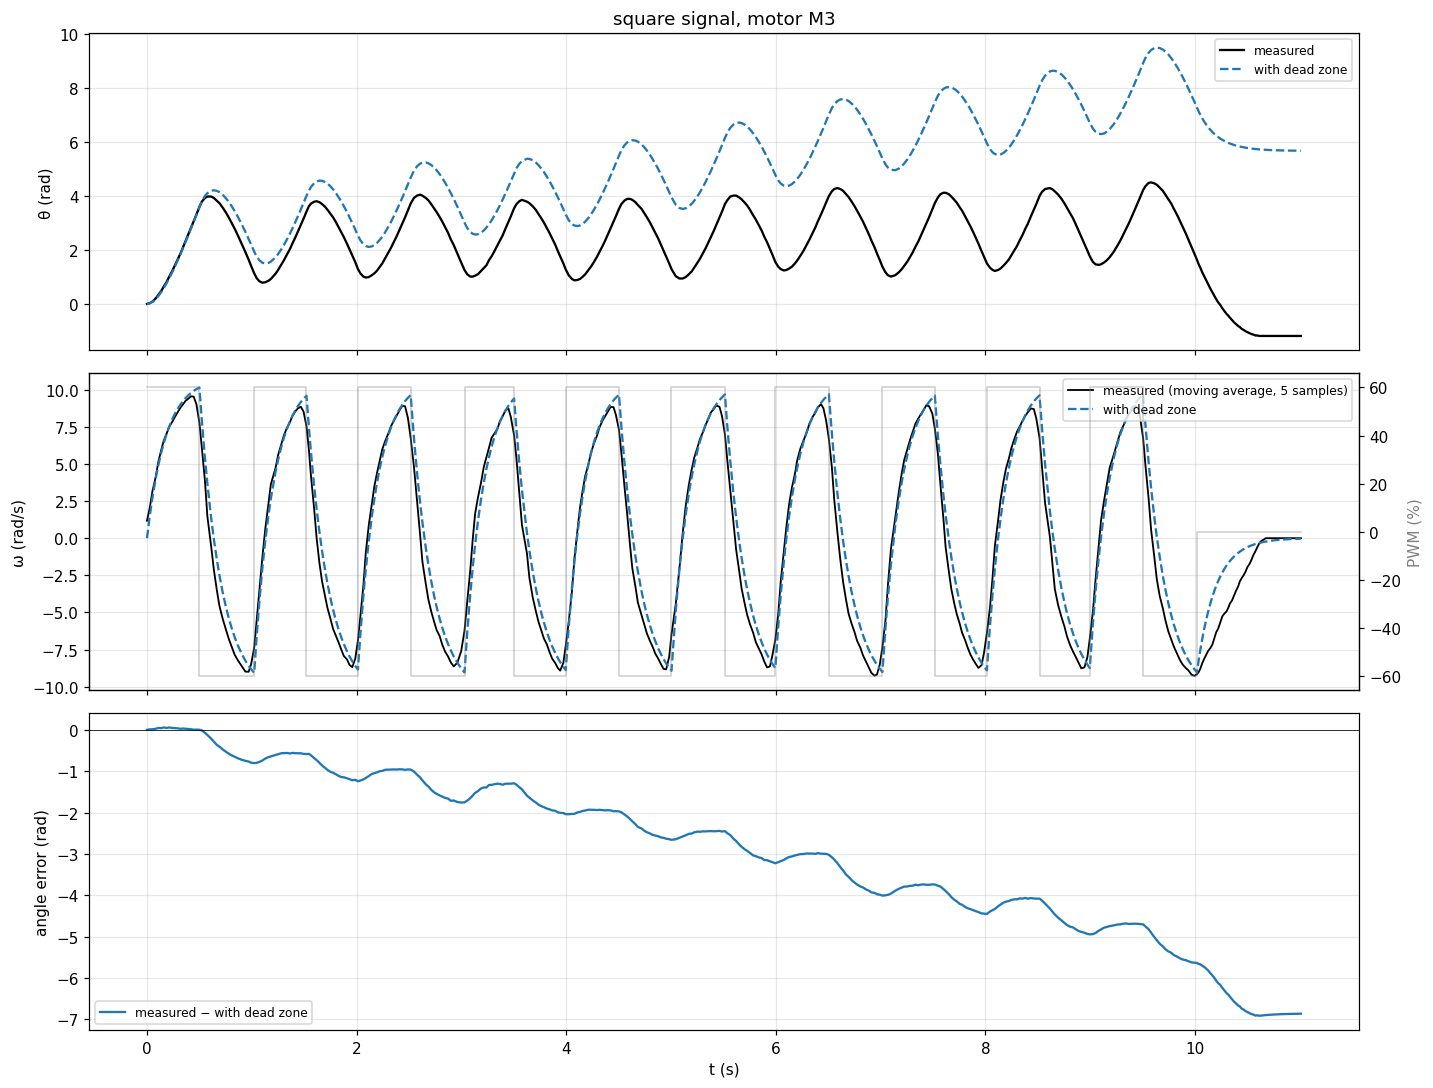

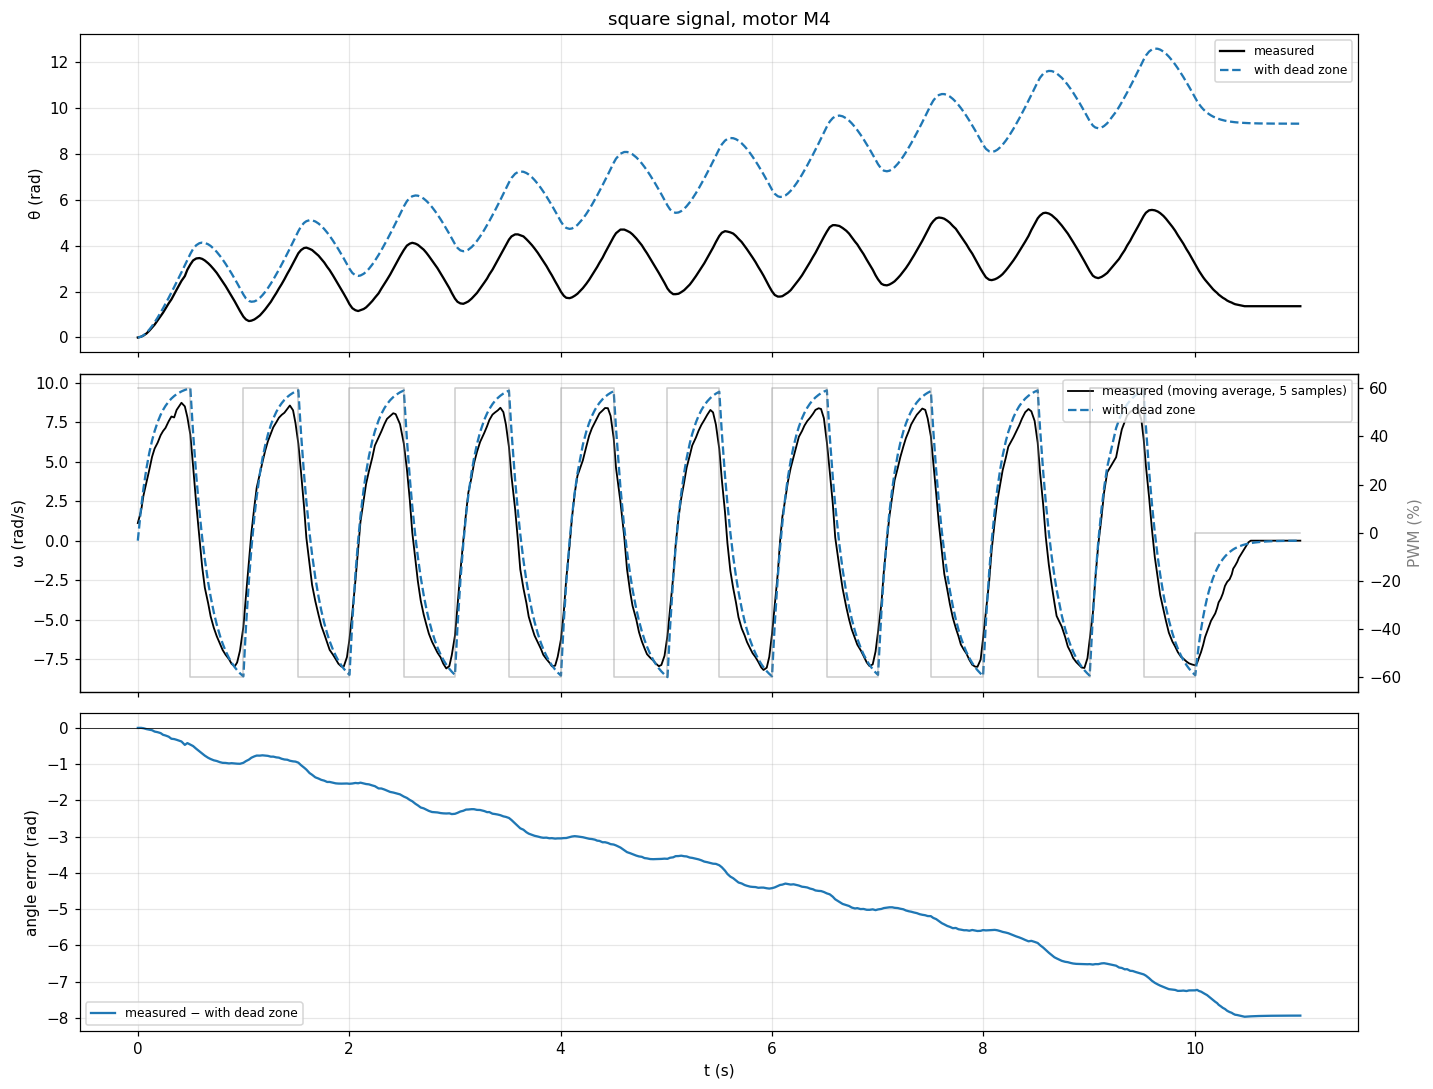

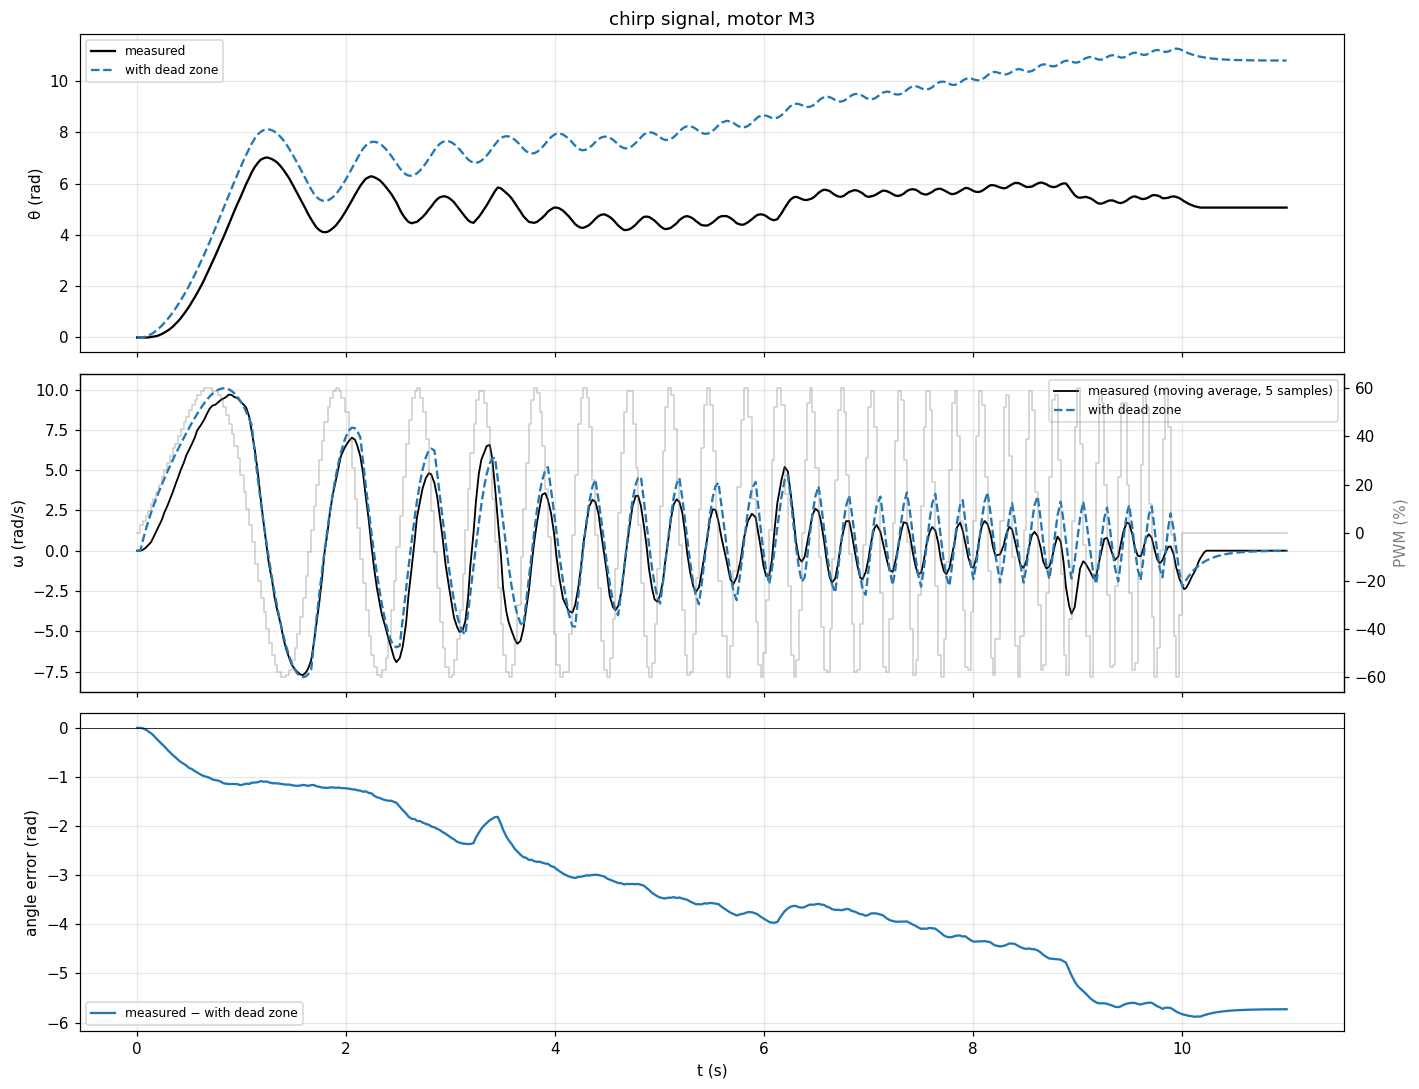

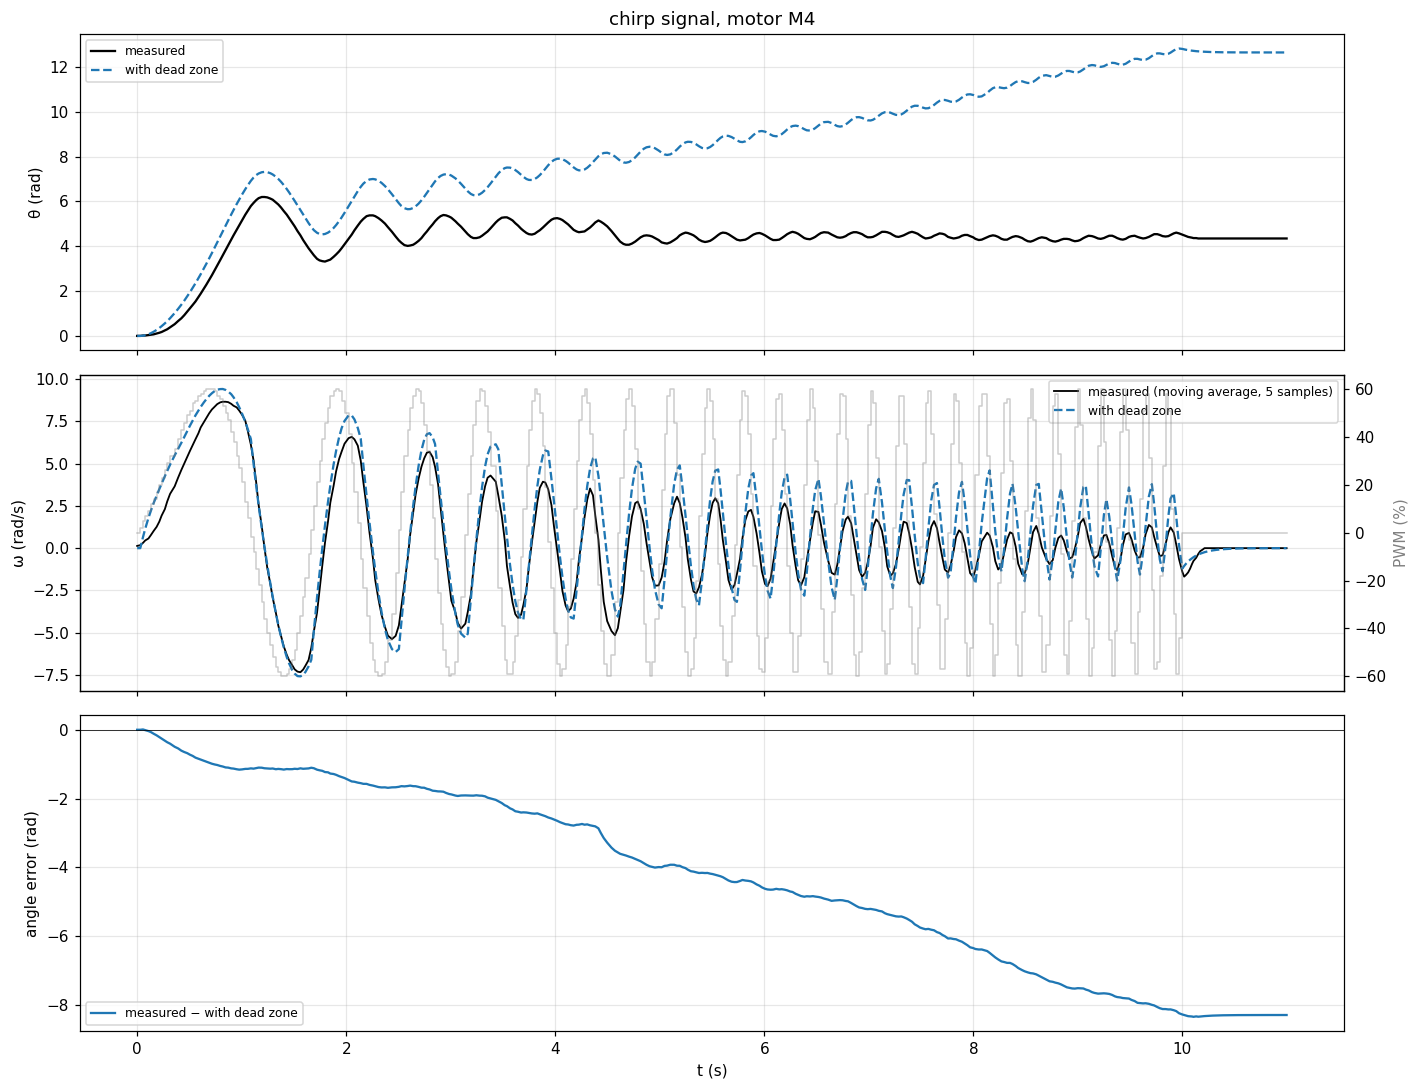

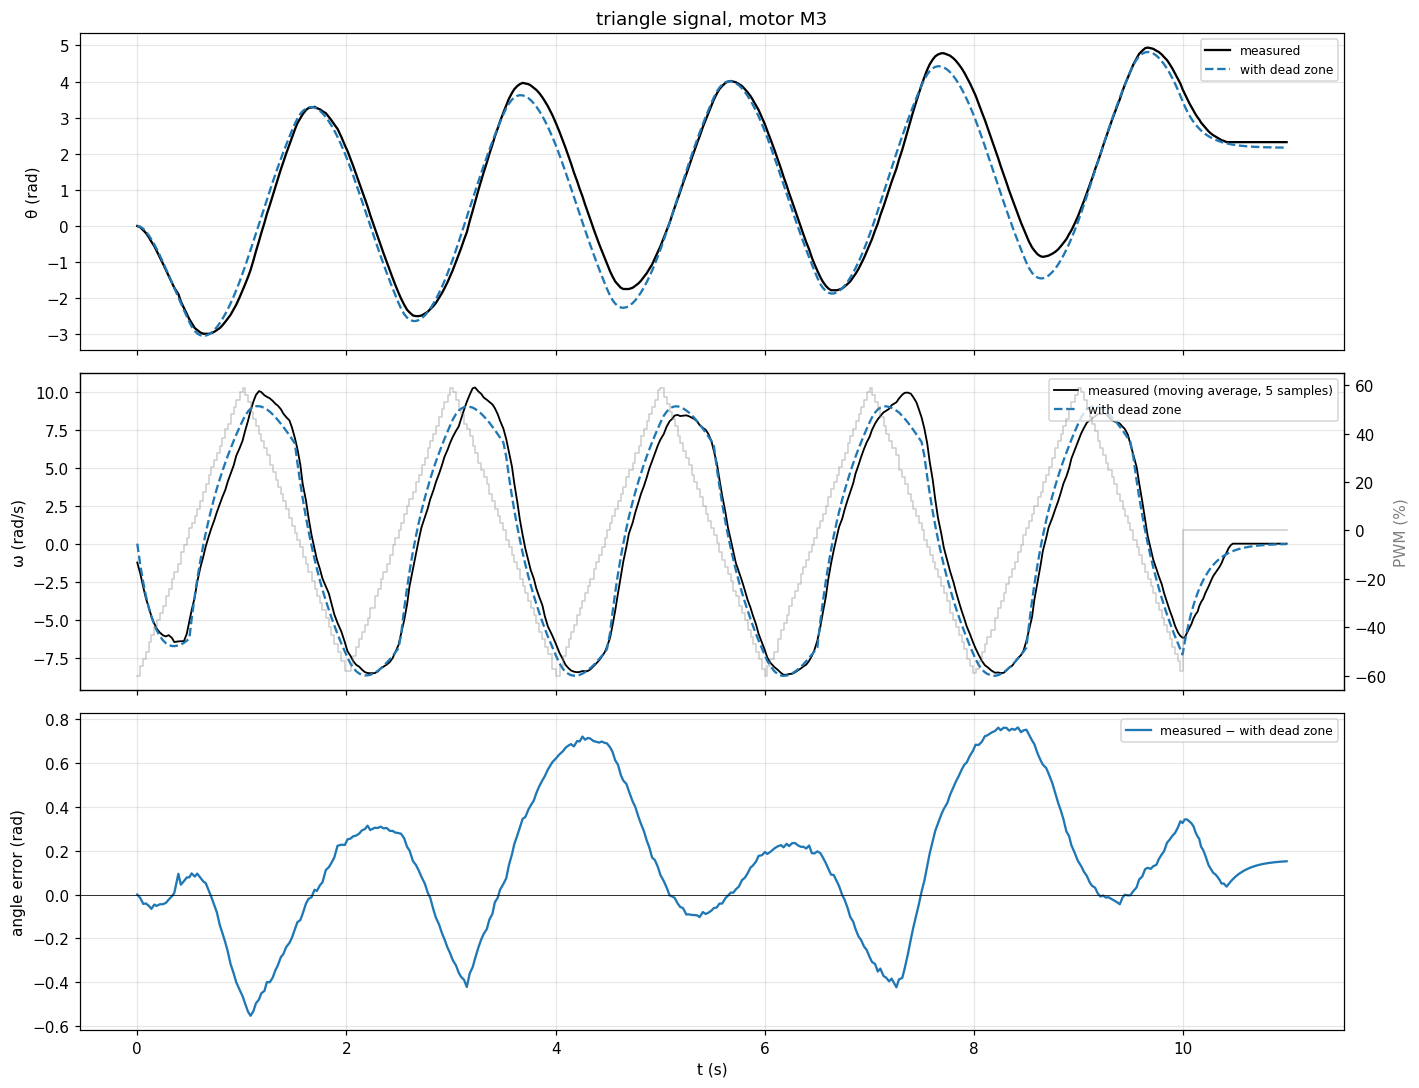

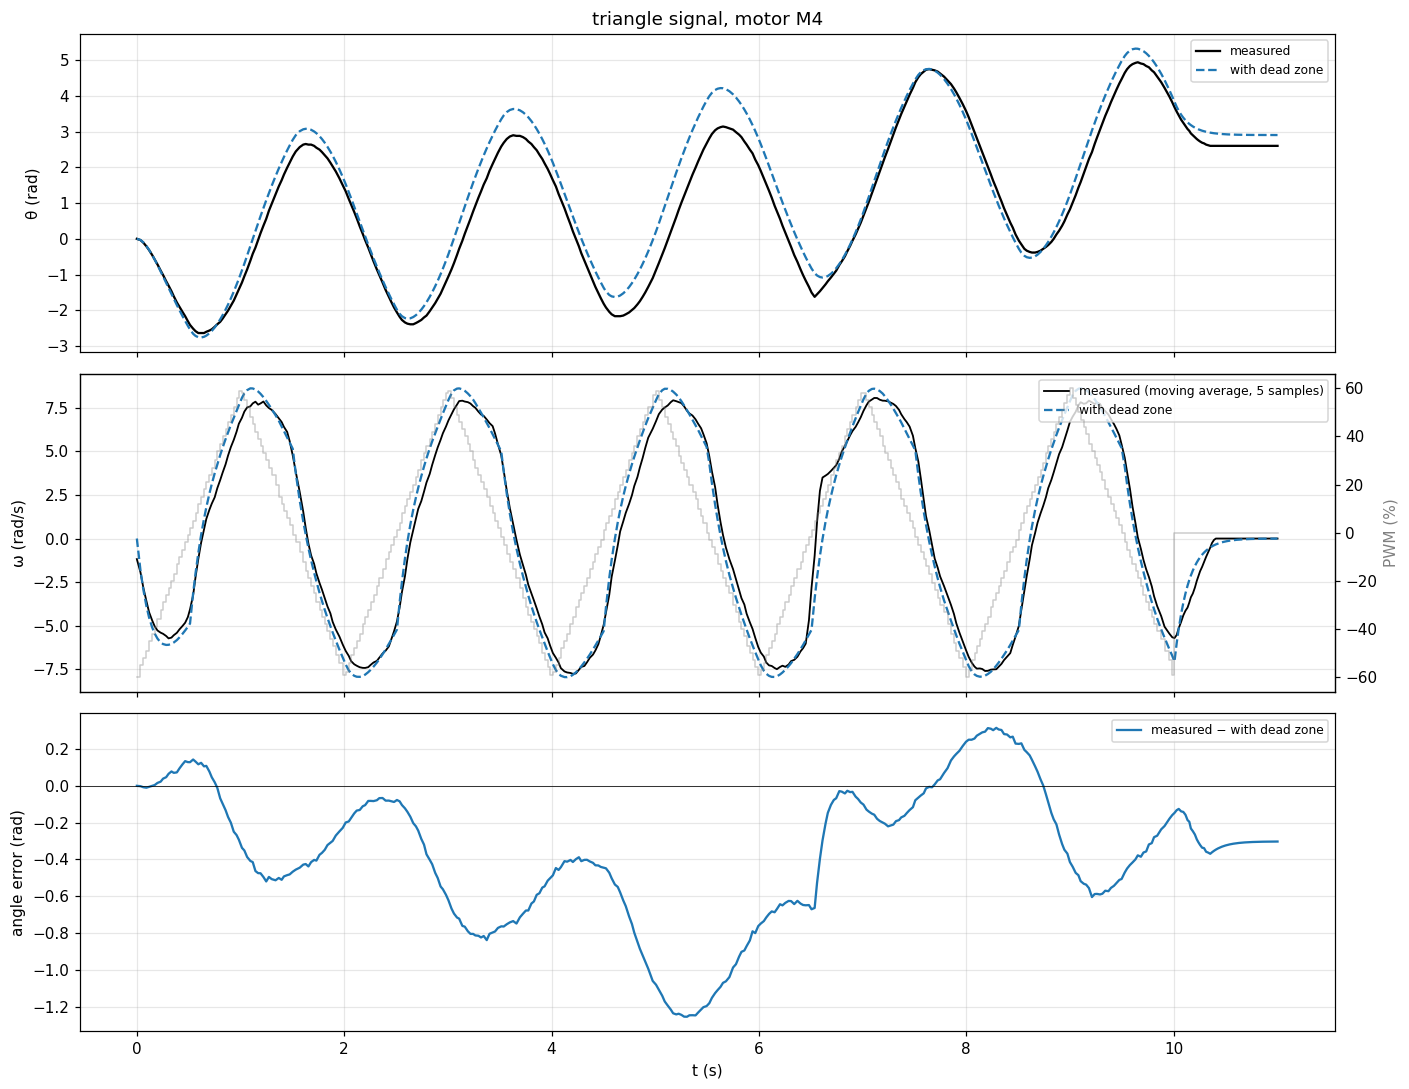

In [8]:
PLOT_MODELS = ['with dead zone']
for (sig, m), r in runs.items():
    fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
    ax[0].plot(r['t'], r['theta'], 'k', lw=1.5, label='measured')
    for name in PLOT_MODELS:
        ax[0].plot(r['t'], r['sim'][name][0], '--', label=name)
    ax[0].set(ylabel='θ (rad)', title=f'{sig} signal, motor {m}')
    ax[0].legend(fontsize=8)

    ax[1].plot(r['t'], r['w'], 'k', lw=1.2, label=f'measured (moving average, {SMOOTH_WINDOW} samples)')
    for name in PLOT_MODELS:
        ax[1].plot(r['t'], r['sim'][name][1], '--', label=name)
    ax[1].set(ylabel='ω (rad/s)')
    ax2 = ax[1].twinx(); ax2.step(r['t'], r['pwm'], where='post', color='grey', alpha=0.4, lw=1)
    ax2.set_ylabel('PWM (%)', color='grey'); ax2.grid(False)
    ax[1].legend(fontsize=8, loc='upper right')

    for name in PLOT_MODELS:
        ax[2].plot(r['t'], r['theta'] - r['sim'][name][0], label=f'measured − {name}')
    ax[2].axhline(0, color='k', lw=0.5)
    ax[2].set(xlabel='t (s)', ylabel='angle error (rad)')
    ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()

if not runs:
    print('Plots appear here after the signal files are added to motor_data/.')


*Figure 1. Each signal and motor: angle (top), speed with the input PWM on the right axis (middle), error measured − simulated (bottom).* ✍️ One sentence per signal: where is the error largest?


## 3. Chirp: amplitude ratio versus frequency
For each cycle of the chirp, the speed amplitude is fitted by least squares and divided by the input amplitude in volts, $U_A = A/100\cdot U_{battery}$. The model prediction is $1/(k_e\sqrt{1+(2\pi f T_m)^2})$ with $k_e$ and $T_m$ from section 1.


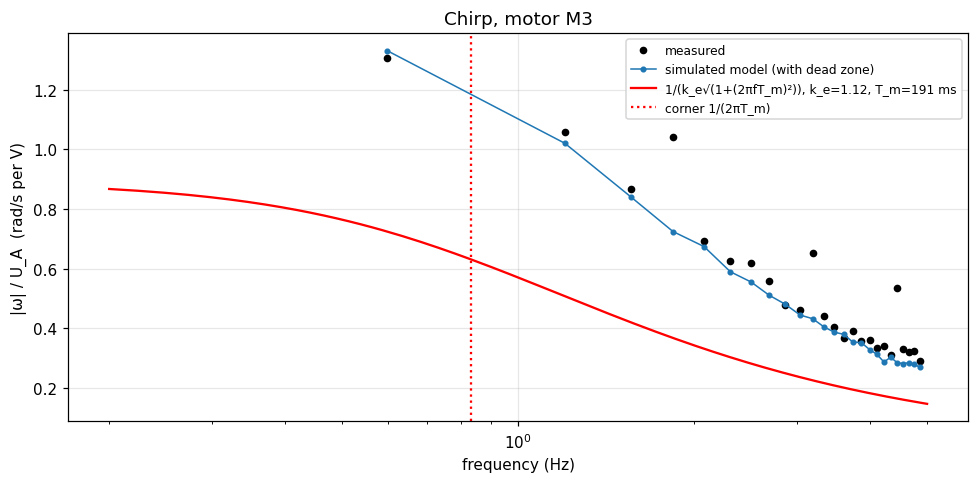

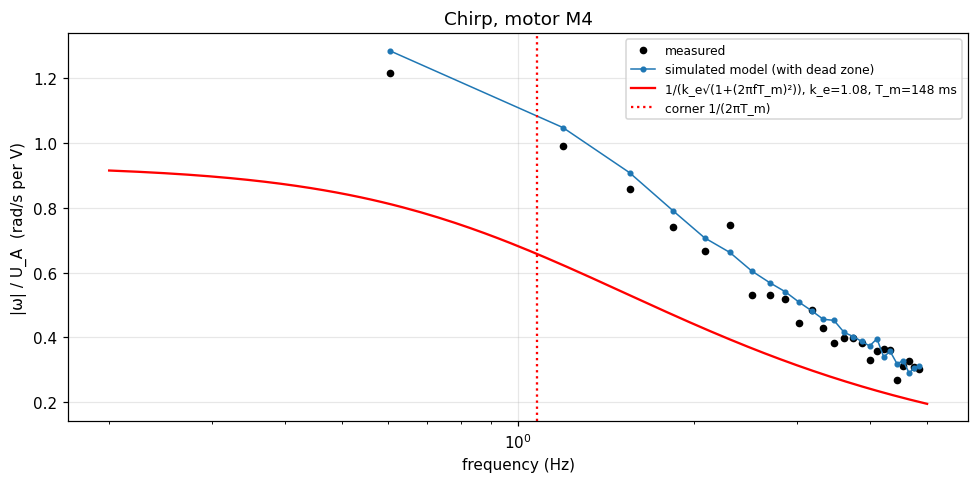

In [9]:

def chirp_gain(t, w, p):
    A, f0, f1, T = p['A'], p['f0'], p['f1'], p['T']
    sel_t = t <= T
    phase = 2 * np.pi * (f0 * t + (f1 - f0) * t ** 2 / (2 * T))
    cycle = np.floor(phase / (2 * np.pi)).astype(int)
    out = []
    for k in range(cycle[sel_t].max()):
        sel = sel_t & (cycle == k)
        if sel.sum() < 6:
            continue
        X = np.column_stack([np.ones(sel.sum()), np.sin(phase[sel]), np.cos(phase[sel])])
        c, *_ = np.linalg.lstsq(X, w[sel], rcond=None)
        out.append((f0 + (f1 - f0) * t[sel].mean() / T, np.hypot(c[1], c[2])))
    return np.array(out)

p = SIGNALS['chirp']
for m in MOTORS:
    if ('chirp', m) not in runs:
        continue
    r = runs[('chirp', m)]
    U_A = p['A'] / 100 * U_batt[m]
    ke = np.mean([P[m][k]['k_e'] for k in P[m]])
    Tm = np.mean([P[m][k]['T_m'] for k in P[m]])
    g = chirp_gain(r['t'], r['w_raw'], p)
    gs = chirp_gain(r['t'], np.gradient(r['sim']['with dead zone'][0], r['t']), p)
    f = np.linspace(p['f0'], p['f1'], 200)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(g[:, 0], g[:, 1] / U_A, 'ko', ms=4, label='measured')
    ax.plot(gs[:, 0], gs[:, 1] / U_A, 'o-', ms=3, lw=1, label='simulated model (with dead zone)')
    ax.plot(f, 1 / (ke * np.sqrt(1 + (2 * np.pi * f * Tm) ** 2)), 'r-',
            label=f'1/(k_e√(1+(2πfT_m)²)), k_e={ke:.2f}, T_m={Tm*1000:.0f} ms')
    ax.axvline(1 / (2 * np.pi * Tm), color='r', ls=':', label='corner 1/(2πT_m)')
    ax.set(xscale='log', xlabel='frequency (Hz)', ylabel='|ω| / U_A  (rad/s per V)', title=f'Chirp, motor {m}')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


*Figure 2. Chirp amplitude ratio against frequency.* ✍️ Does the amplitude fall where $1/(2\pi T_m)$ predicts? Why is the measured ratio above the formula (hint: the offset $b$ in the speed line)?

## 4. Summary

In [10]:

summary = res.pivot_table(index=['signal', 'motor'], columns='model', values=['speed_fit_pct', 'speed_RMSE'])
print('Fit % and RMSE (rad/s) of the speed on every signal:')
print(summary.round(2).to_string())


Fit % and RMSE (rad/s) of the speed on every signal:
                   speed_RMSE                    speed_fit_pct                  
model          with dead zone without dead zone with dead zone without dead zone
signal   motor                                                                  
chirp    M3              1.15              1.15          65.77             65.77
         M4              1.27              1.27          58.14             58.14
square   M3              1.38              1.38          77.66             77.66
         M4              1.23              1.23          78.45             78.45
triangle M3              0.89              0.89          85.26             85.26
         M4              0.83              0.83          84.26             84.26



### Analysis — ✍️ write in your own words

**How well does the identified model reproduce each signal?** Give the fit % for square, chirp and triangle (table above) and compare them.

**What did each signal show that the step series did not?** Square: repeated reversals in both directions. Chirp: how the response falls with frequency, a direct check of $T_m$. Triangle: slow sweep through every speed, including the zero crossing.

**Dead zone:** do the results with and without it differ? What does that say about the dead zone of these motors?
